# Step 2 (Week 2): water maps and first flood maps

**Goal:** find water on Sept 6 (before) and Sept 18 (after), then call **flood** the water that is new on Sept 18.

New words:
- **Water index:** one number per pixel from two bands, (a − b) / (a + b), between −1 and +1. NDWI uses green and near-infrared (NIR). MNDWI uses green and shortwave infrared (SWIR).
- **Cutoff:** the line that turns a number into yes/no, like "above 100°F = fever".
- **Blackwater river:** a river stained tea-brown by fallen leaves. The Lumber is one.

In [1]:
import sys, importlib
from pathlib import Path
sys.path.insert(0, str(Path('..') / 'src'))
import numpy as np, pandas as pd
from IPython.display import Image, display
import hls
step2 = importlib.import_module('02_water_maps')
hls.login()
bbox = hls.STUDY_AREAS[hls.STUDY_AREA]
before = step2.load_day(bbox, step2.BEFORE)
after = step2.load_day(bbox, step2.AFTER)
use = before['usable'] & after['usable']
print(f"usable on both days: {use.mean():.0%}")

/Users/co2/Downloads/nc-hls-mapper/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


2018-09-06: HLS.S30.T17SPU.2018249T155859.v2.0


2018-09-18: HLS.S30.T17SPU.2018261T154911.v2.0


usable on both days: 78%


## Part A: the textbook water indexes (cutoff 0)

In [2]:
rows = []
for name, fn in (('NDWI', hls.ndwi), ('MNDWI', hls.mndwi)):
    wb = (fn(before['bands']).values > 0) & use
    wa = (fn(after['bands']).values > 0) & use
    rows.append({'index': name, 'water before km2': step2.km2(wb), 'water after km2': step2.km2(wa), 'new flood km2': step2.km2(wa & ~wb)})
pd.DataFrame(rows).round(1)

,index,water before km2,water after km2,new flood km2
0,NDWI,1.1,0.5,0.2
1,MNDWI,1.6,1.8,1.0


That looks wrong: NDWI finds *less* water after a hurricane. NASA's own Fmask water flag finds much more. What do the pixels Fmask calls water actually look like?

In [3]:
m_after = hls.mndwi(after['bands']).values
fm_water = ((after['fmask'].values & (1 << 5)) > 0) & use
groups = {'land (everything else)': use & ~fm_water & ~(m_after > 0),
          'water our index caught': (m_after > 0) & use,
          'Fmask water our index missed': fm_water & (m_after <= 0)}
pd.DataFrame([{ 'group': g, 'km2': step2.km2(m),
                **{b: float(np.nanmedian(after['bands'][b].values[m])) for b in ('green', 'nir', 'swir1')}}
              for g, m in groups.items()]).round(3)

,group,km2,green,nir,swir1
0,land (everything else),304.330,0.039,0.260,0.161
1,water our index caught,1.849,0.012,0.015,0.008
2,Fmask water our index missed,6.517,0.009,0.036,0.022


**The missed water is darker in green than in SWIR.** Tea-colored blackwater soaks up green light, so the index formula says "land". But *every* kind of water is very dark in NIR. In those pixels NIR fell from about 0.27 to 0.04 between the two days.

## Part B: two rules based on near-infrared
1. **Dark-in-NIR:** water = NIR < 0.10. Flood = water after that was not water before.
2. **NIR-drop:** flood = NIR fell to less than half its Sept 6 value (and it was not water before).

In [4]:
wb_dark, flood_dark = step2.flood_dark_nir(before, after, use)
wb_drop, flood_drop = step2.flood_nir_drop(before, after, use)
both, either = flood_dark & flood_drop, flood_dark | flood_drop
print(f"dark-in-NIR flood: {step2.km2(flood_dark):.1f} km2")
print(f"NIR-drop flood:    {step2.km2(flood_drop):.1f} km2")
print(f"overlap (both / either): {both.sum() / either.sum():.0%}")

dark-in-NIR flood: 11.3 km2
NIR-drop flood:    16.5 km2
overlap (both / either): 63%


The histograms have **no clean gap** between water and land (many pixels are part water, part trees), so the cutoff matters:

In [5]:
pd.DataFrame([{'rule': 'dark-in-NIR', 'cutoff': c, 'new flood km2': step2.km2(step2.flood_dark_nir(before, after, use, c)[1])} for c in (0.05, 0.08, 0.10, 0.12, 0.15)]
           + [{'rule': 'NIR-drop', 'cutoff': r, 'new flood km2': step2.km2(step2.flood_nir_drop(before, after, use, r)[1])} for r in (0.3, 0.4, 0.5, 0.6, 0.7)]).round({'new flood km2': 1})

,rule,cutoff,new flood km2
0,dark-in-NIR,0.05,5.2
1,dark-in-NIR,0.08,8.7
2,dark-in-NIR,0.10,11.3
3,dark-in-NIR,0.12,14.2
4,dark-in-NIR,0.15,20.5
5,NIR-drop,0.30,8.3
6,NIR-drop,0.40,11.9
7,NIR-drop,0.50,16.5
8,NIR-drop,0.60,23.4
9,NIR-drop,0.70,37.7


## All pictures (the full script rebuilds them)

2018-09-06: HLS.S30.T17SPU.2018249T155859.v2.0


2018-09-18: HLS.S30.T17SPU.2018261T154911.v2.0


Box pixels: 443,096; usable on BOTH days: 78%

Water and flood areas (only pixels usable on both days):
                method  water before km2  water after km2  new flood km2
              NDWI > 0               1.1              0.5            0.2
             MNDWI > 0               1.6              1.8            1.0
             NIR < 0.1               2.3             13.5           11.3
NIR after/before < 0.5               2.3             18.7           16.5

NIR rules agree: 10.7 km2 flagged by both, 17.0 by either -> overlap 63%
  only dark-in-NIR: 0.5 km2, only NIR-drop: 5.7 km2

Sanity check vs Fmask water flag: Fmask new water 6.0 km2; share of it our rules also flag: dark-in-NIR 91%, NIR-drop 92%

How the flood area changes with the cutoff:
       rule  cutoff  new flood km2
dark-in-NIR    0.05            5.2
dark-in-NIR    0.08            8.7
dark-in-NIR    0.10           11.3
dark-in-NIR    0.12           14.2
dark-in-NIR    0.15           20.5
   NIR-drop    0.30        


Saved figures/02_*.png, results/02_*.csv, data/02_flood_*.tif


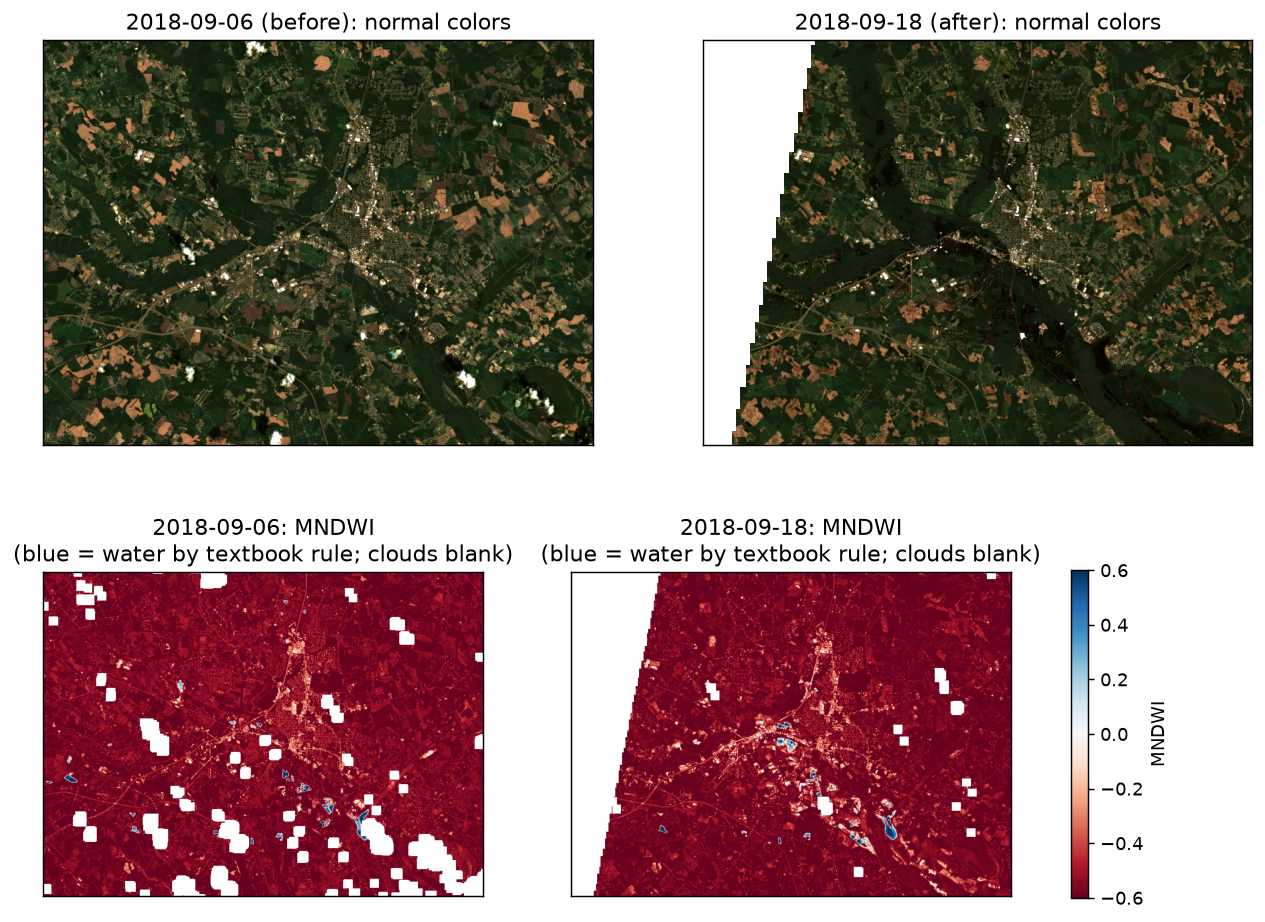

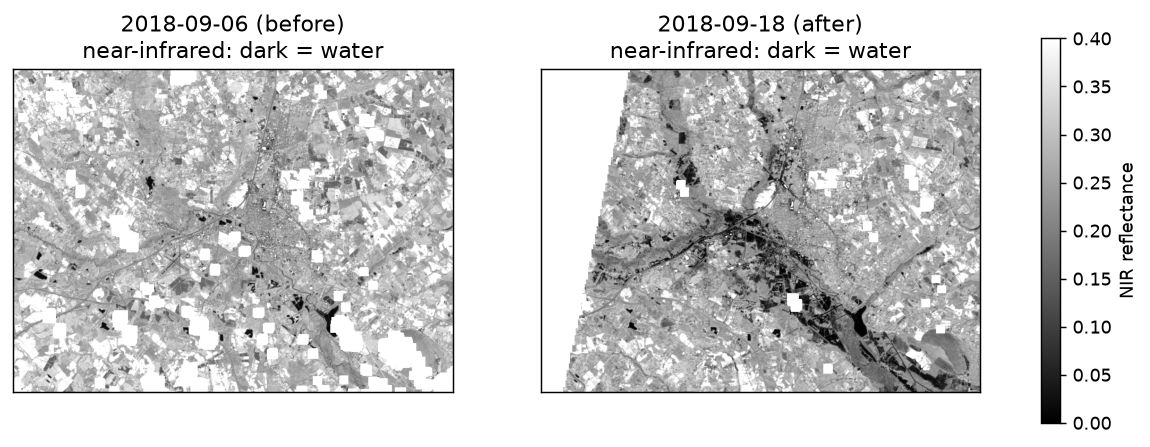

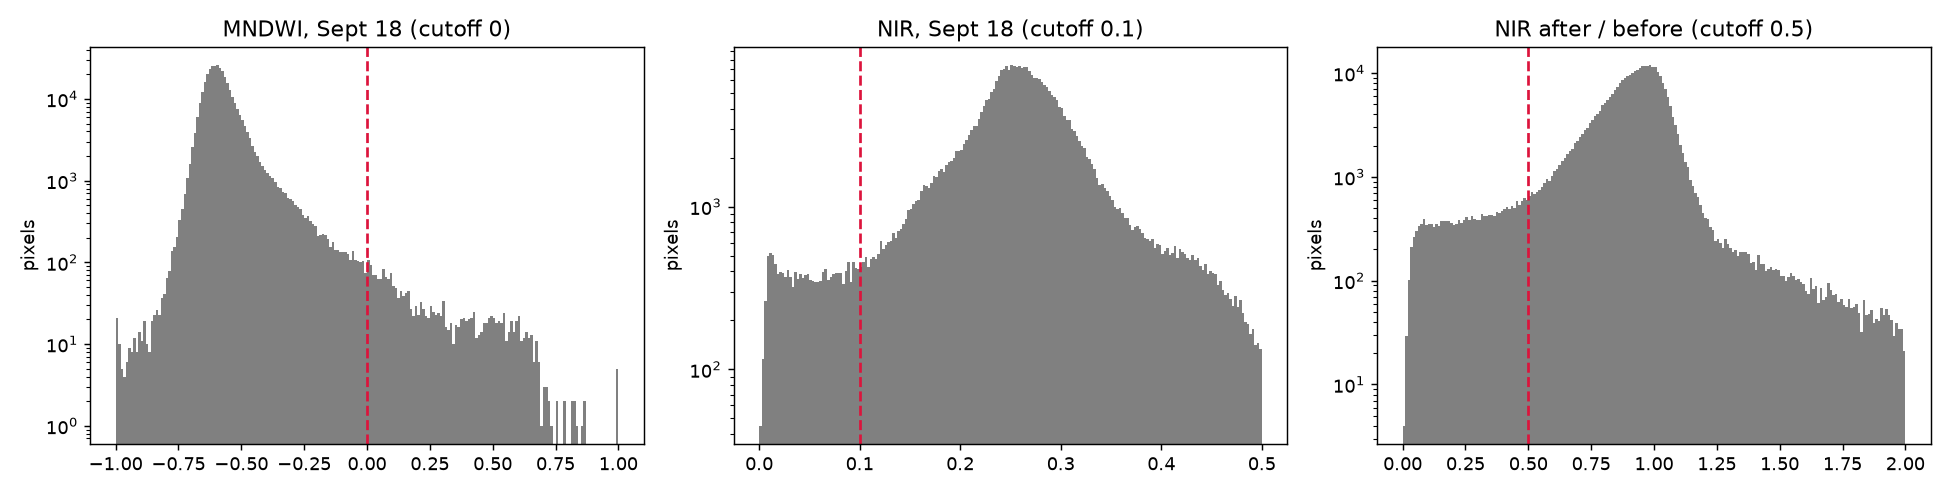

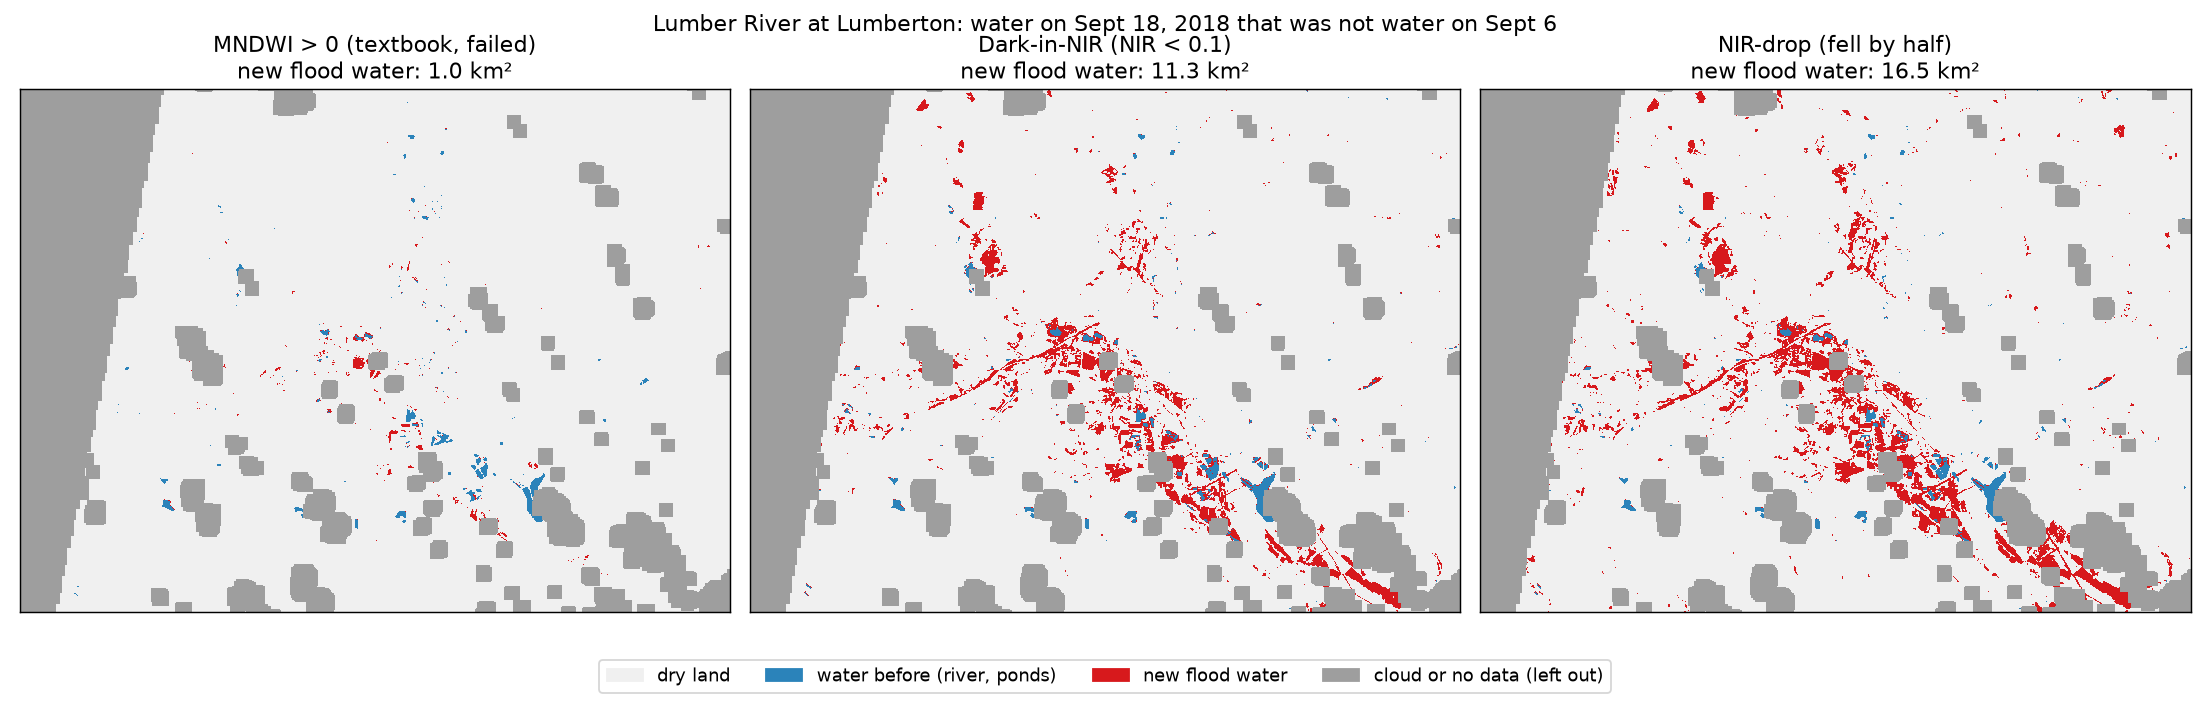

In [6]:
step2.main()
for f in ('02_before_after_mndwi', '02_nir_before_after', '02_histograms', '02_flood_maps_compared'):
    display(Image(filename=f'../figures/{f}.png'))

## What we learned
- **The textbook method failed here.** NDWI/MNDWI with cutoff 0 found only about 1 km² of new water. The Lumber's tea-colored water is darker in green than in SWIR, so the formulas call it land.
- **NIR works for any water color.** Dark-in-NIR finds 11.3 km² of new flood water and NIR-drop finds 16.5 km². Both follow the river corridor.
- The two rules agree on 10.7 km²; NIR-drop adds 5.7 km² more, mostly scattered patches. We can't yet say which is right.
- **The cutoff matters a lot** (dark-in-NIR: 5 to 21 km² for cutoffs 0.05 to 0.15). An honest answer is a range, until we check against a reference map (Week 3).